In [11]:
import pandas as pd

df = pd.read_csv("Sample - Superstore.csv", encoding="windows-1252")

print("Total Rows and Columns:", df.shape)
df.head()

Total Rows and Columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
import pandas as pd
import numpy as np

In [14]:
# Check missing values and duplicates
print("Missing Values in each column:\n", df.isnull().sum())
print("\nDuplicate Rows before cleaning:", df.duplicated().sum())

Missing Values in each column:
 Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate Rows before cleaning: 0


In [15]:
# Remove duplicates
df = df.drop_duplicates()

print("Total Rows after removing duplicates:", len(df))


Total Rows after removing duplicates: 9994


In [16]:
# 3. Convert dates and extract Year & Month
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Order_Year'] = df['Order Date'].dt.year
df['Order_Month'] = df['Order Date'].dt.month_name()


In [17]:
# Show output of new date columns
df[['Order Date', 'Ship Date', 'Order_Year', 'Order_Month']].head()

,Order Date,Ship Date,Order_Year,Order_Month
0,2016-11-08,2016-11-11,2016,November
1,2016-11-08,2016-11-11,2016,November
2,2016-06-12,2016-06-16,2016,June
3,2015-10-11,2015-10-18,2015,October
4,2015-10-11,2015-10-18,2015,October


In [18]:
# 4. Create 'Profit_Status' column using NumPy
df['Profit_Status'] = np.where(df['Profit'] > 0, 'Profit', 'Loss')


In [19]:
# Show count of Profit vs Loss orders and sample rows
print(df['Profit_Status'].value_counts())
df[['Category', 'Sub-Category', 'Sales', 'Profit', 'Profit_Status']].head()

Profit_Status
Profit    8058
Loss      1936
Name: count, dtype: int64


,Category,Sub-Category,Sales,Profit,Profit_Status
0,Furniture,Bookcases,261.9600,41.9136,Profit
1,Furniture,Chairs,731.9400,219.5820,Profit
2,Office Supplies,Labels,14.6200,6.8714,Profit
3,Furniture,Tables,957.5775,-383.0310,Loss
4,Office Supplies,Storage,22.3680,2.5164,Profit


In [20]:
# 5. Drop unnecessary columns and save cleaned data for SQL & Power BI
df = df.drop(columns=['Row ID', 'Country'])
df.to_csv("cleaned_superstore.csv", index=False)

print("Step 1 Done! Cleaned file 'cleaned_superstore.csv' is saved.")
print("Final Columns:", list(df.columns))
df.head()


Step 1 Done! Cleaned file 'cleaned_superstore.csv' is saved.
Final Columns: ['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Order_Year', 'Order_Month', 'Profit_Status']


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Postal Code,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order_Year,Order_Month,Profit_Status
0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,November,Profit
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,42420,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,November,Profit
2,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,Los Angeles,California,90036,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,June,Profit
3,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,October,Loss
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,33311,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,October,Profit


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
# Set visual theme for professional charts
sns.set_style("whitegrid")

In [26]:
# Overall business summary
print("Overall Financial Summary:")
df[['Sales', 'Quantity', 'Discount', 'Profit']].describe().round(2)


Overall Financial Summary:


,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


In [27]:
# Group data by Category
cat_summary = df.groupby('Category')[['Sales', 'Profit']].sum().reset_index()
print(cat_summary)


          Category        Sales       Profit
0        Furniture  741999.7953   18451.2728
1  Office Supplies  719047.0320  122490.8008
2       Technology  836154.0330  145454.9481


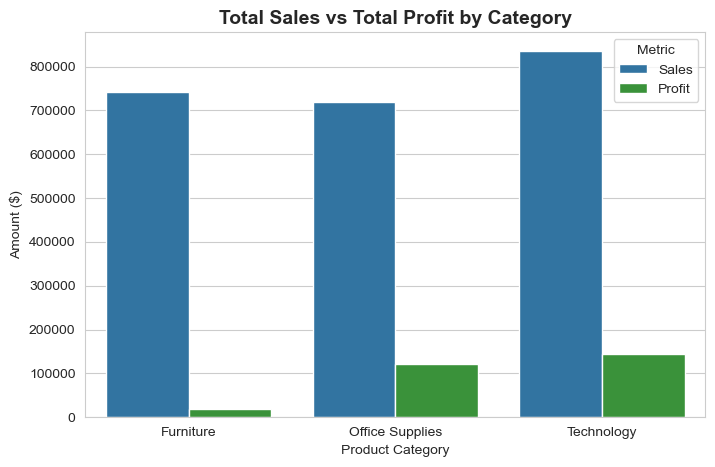

In [28]:
# Plot Sales vs Profit by Category
plt.figure(figsize=(8, 5))
cat_melted = cat_summary.melt(id_vars='Category', var_name='Metric', value_name='Amount')
sns.barplot(data=cat_melted, x='Category', y='Amount', hue='Metric', palette=['#1f77b4', '#2ca02c'])

plt.title('Total Sales vs Total Profit by Category', fontsize=14, fontweight='bold')
plt.ylabel('Amount ($)')
plt.xlabel('Product Category')
plt.show()


In [29]:
# Group profit by Sub-Category and sort
sub_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values()
print("Top 5 Loss-Making Sub-Categories:\n", sub_profit.head(5))

Top 5 Loss-Making Sub-Categories:
 Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Fasteners      949.5182
Machines      3384.7569
Name: Profit, dtype: float64


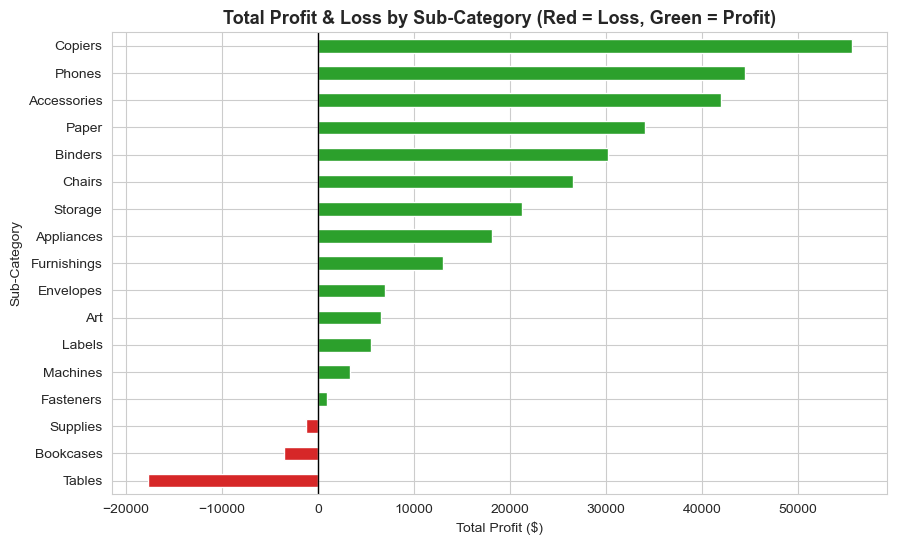

In [30]:
# Horizontal Bar Chart with Red for Loss and Green for Profit
plt.figure(figsize=(10, 6))
colors = ['#d62728' if x < 0 else '#2ca02c' for x in sub_profit]
sub_profit.plot(kind='barh', color=colors)

plt.title('Total Profit & Loss by Sub-Category (Red = Loss, Green = Profit)', fontsize=13, fontweight='bold')
plt.xlabel('Total Profit ($)')
plt.ylabel('Sub-Category')
plt.axvline(0, color='black', linewidth=1)
plt.show()


In [31]:
# Average profit at each discount level
discount_impact = df.groupby('Discount')['Profit'].mean().reset_index()
print(discount_impact)

    Discount      Profit
0       0.00   66.900292
1       0.10   96.055074
2       0.15   27.288298
3       0.20   24.702572
4       0.30  -45.679636
5       0.32  -88.560656
6       0.40 -111.927429
7       0.45 -226.646464
8       0.50 -310.703456
9       0.60  -43.077212
10      0.70  -95.874060
11      0.80 -101.796797


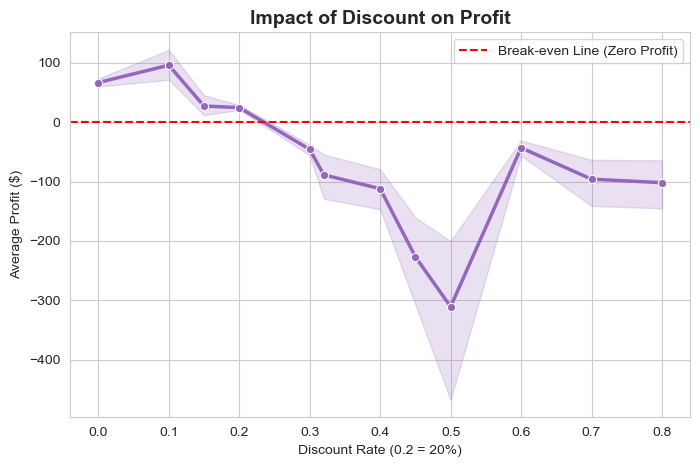

In [32]:
# Line plot showing profit drop as discount increases
plt.figure(figsize=(8, 5))
sns.lineplot(data=df, x='Discount', y='Profit', marker='o', color='#9467bd', linewidth=2.5)
plt.axhline(0, color='red', linestyle='--', label='Break-even Line (Zero Profit)')

plt.title('Impact of Discount on Profit', fontsize=14, fontweight='bold')
plt.xlabel('Discount Rate (0.2 = 20%)')
plt.ylabel('Average Profit ($)')
plt.legend()
plt.show()


In [33]:
# Region and Segment summary
region_seg = df.groupby(['Region', 'Segment'])['Sales'].sum().unstack()
print(region_seg.round(2))

Segment   Consumer  Corporate  Home Office
Region                                    
Central  252031.43  157995.81     91212.64
East     350908.17  200409.35    127463.73
South    195580.97  121885.93     74255.00
West     362880.77  225855.27    136721.78


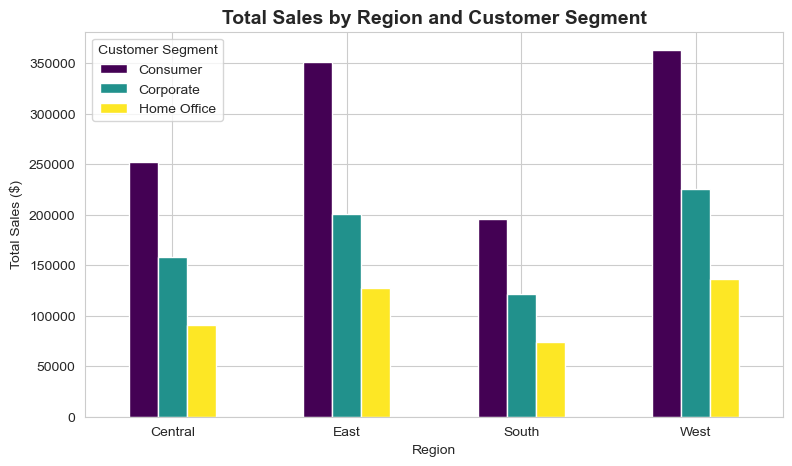

In [34]:
# Stacked/Grouped Bar Chart
region_seg.plot(kind='bar', figsize=(9, 5), colormap='viridis')
plt.title('Total Sales by Region and Customer Segment', fontsize=14, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.legend(title='Customer Segment')
plt.show()


In [35]:
# Yearly Sales and Profit
yearly_trend = df.groupby('Order_Year')[['Sales', 'Profit']].sum().reset_index()
print(yearly_trend.round(2))

   Order_Year      Sales    Profit
0        2014  484247.50  49543.97
1        2015  470532.51  61618.60
2        2016  609205.60  81795.17
3        2017  733215.26  93439.27


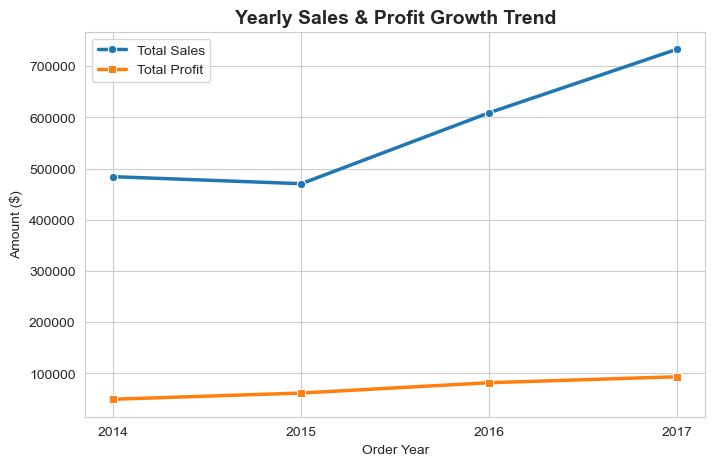

In [36]:
# Line chart for Yearly Trend
plt.figure(figsize=(8, 5))
sns.lineplot(data=yearly_trend, x='Order_Year', y='Sales', marker='o', label='Total Sales', linewidth=2.5)
sns.lineplot(data=yearly_trend, x='Order_Year', y='Profit', marker='s', label='Total Profit', linewidth=2.5)

plt.title('Yearly Sales & Profit Growth Trend', fontsize=14, fontweight='bold')
plt.xlabel('Order Year')
plt.ylabel('Amount ($)')
plt.xticks(yearly_trend['Order_Year'])
plt.legend()
plt.show()
